# SCY1102 · Semana 13
## Monitor de Proyecto · Act. 3.2

**Objetivo:** transformar el seguimiento del proyecto en decisiones.

En este Colab trabajaremos en el mismo orden visto en la PPT:

**Hito → Tarea → Responsable → Dependencia → Estado/Avance → Desviación → Acción → KPI → Dashboard**

> Regla de trabajo: el código calcula; el equipo interpreta y decide.

## 0. Antes de comenzar

Tengan a mano la **microactividad de clase**.  
Ya deberían haber definido:

- 1 hito real de su proyecto;
- 3 a 5 tareas;
- responsables;
- dependencias;
- estado actual y porcentaje de avance;
- una posible desviación.

Primero veremos un ejemplo con **EduAlert**.  
Después reemplazarán los datos por los de su propio proyecto.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

# PARTE 1 · EJEMPLO EDUALERT

## 1. Hito

Un **hito** es un resultado importante y verificable.

En EduAlert trabajaremos con este hito:

**H1 · Dataset limpio y validado**

No es una tarea. Es el resultado que esperamos demostrar.

In [2]:
hito = "H1 · Dataset limpio y validado"
evidencia_hito = "Notebook ejecutado + revisión de nulos + variables validadas"

print("HITO:", hito)
print("EVIDENCIA:", evidencia_hito)

HITO: H1 · Dataset limpio y validado
EVIDENCIA: Notebook ejecutado + revisión de nulos + variables validadas


## 2. Tareas + responsables + dependencias

Ahora descomponemos el hito en tareas concretas.

Observe que cada tarea tiene:

- responsable;
- horas planificadas;
- horas reales;
- estado;
- avance;
- dependencia;
- evidencia.

In [3]:
tareas = pd.DataFrame([
    {
        "id": "T1",
        "hito": "H1 Dataset limpio",
        "tarea": "Revisar valores nulos",
        "responsable": "Ana",
        "horas_plan": 2,
        "horas_real": 2,
        "estado": "Completada",
        "avance_pct": 100,
        "dependencia": "",
        "evidencia": "Reporte de nulos"
    },
    {
        "id": "T2",
        "hito": "H1 Dataset limpio",
        "tarea": "Limpiar registros",
        "responsable": "Ana",
        "horas_plan": 2,
        "horas_real": 5,
        "estado": "En progreso",
        "avance_pct": 70,
        "dependencia": "T1",
        "evidencia": "DataFrame parcialmente limpio"
    },
    {
        "id": "T3",
        "hito": "H2 Modelo base",
        "tarea": "Definir X e y",
        "responsable": "Carla",
        "horas_plan": 1,
        "horas_real": 0,
        "estado": "Pendiente",
        "avance_pct": 0,
        "dependencia": "T2",
        "evidencia": ""
    },
    {
        "id": "T4",
        "hito": "H2 Modelo base",
        "tarea": "Entrenar modelo base",
        "responsable": "Pedro",
        "horas_plan": 3,
        "horas_real": 0,
        "estado": "Pendiente",
        "avance_pct": 0,
        "dependencia": "T3",
        "evidencia": ""
    },
    {
        "id": "T5",
        "hito": "H3 Validación",
        "tarea": "Evaluar métricas",
        "responsable": "Diego",
        "horas_plan": 2,
        "horas_real": 0,
        "estado": "Pendiente",
        "avance_pct": 0,
        "dependencia": "T4",
        "evidencia": ""
    }
])

tareas

,id,hito,tarea,responsable,horas_plan,horas_real,estado,avance_pct,dependencia,evidencia
0,T1,H1 Dataset limpio,Revisar valores nulos,Ana,2,2,Completada,100,,Reporte de nulos
1,T2,H1 Dataset limpio,Limpiar registros,Ana,2,5,En progreso,70,T1,DataFrame parcialmente limpio
2,T3,H2 Modelo base,Definir X e y,Carla,1,0,Pendiente,0,T2,
3,T4,H2 Modelo base,Entrenar modelo base,Pedro,3,0,Pendiente,0,T3,
4,T5,H3 Validación,Evaluar métricas,Diego,2,0,Pendiente,0,T4,


### Pregunta de interpretación

Antes de ejecutar la siguiente celda:

**¿Qué tarea creen que está poniendo en riesgo al resto del proyecto? ¿Por qué?**

**Respuesta:** T2 · *Limpiar registros*. Está en progreso con 5 h reales sobre 2 h planificadas y T3 depende de ella; mientras no termine, T3, T4 y T5 no pueden comenzar. Además Ana tiene T1 y T2, lo que concentra la carga en una sola persona.

## 3. Estado + avance

El estado dice **dónde está** la tarea.  
El porcentaje intenta mostrar **cuánto falta**.

El avance general se calculará como el promedio simple del porcentaje de avance de las tareas.

In [4]:
avance_general = tareas["avance_pct"].mean()

print(f"AVANCE GENERAL: {avance_general:.1f}%")
print()
print(tareas[["id", "tarea", "estado", "avance_pct"]].to_string(index=False))

AVANCE GENERAL: 34.0%

id                 tarea      estado  avance_pct
T1 Revisar valores nulos  Completada         100
T2     Limpiar registros En progreso          70
T3         Definir X e y   Pendiente           0
T4  Entrenar modelo base   Pendiente           0
T5      Evaluar métricas   Pendiente           0


## 4. Dependencias y bloqueos

Una tarea se considera **bloqueada** cuando depende de otra que todavía no está completada.

In [5]:
estado_por_id = dict(zip(tareas["id"], tareas["estado"]))

def esta_bloqueada(dep):
    if dep == "" or pd.isna(dep):
        return False
    return estado_por_id.get(dep) != "Completada"

tareas["bloqueada"] = tareas["dependencia"].apply(esta_bloqueada)

print(tareas[["id", "tarea", "dependencia", "estado", "bloqueada"]].to_string(index=False))

id                 tarea dependencia      estado  bloqueada
T1 Revisar valores nulos              Completada      False
T2     Limpiar registros          T1 En progreso      False
T3         Definir X e y          T2   Pendiente       True
T4  Entrenar modelo base          T3   Pendiente       True
T5      Evaluar métricas          T4   Pendiente       True


### Pregunta de interpretación

**¿Qué tarea produce el primer bloqueo de la cadena?**

No respondan solo con el ID. Expliquen la causa.

**Respuesta:** el primer bloqueo lo produce **T2**. T3 (*Definir X e y*) depende de T2 y T2 no está Completada (70 %), porque se encontraron más valores faltantes de lo previsto. Como T4 depende de T3 y T5 de T4, el bloqueo se propaga a toda la cadena: 3 tareas bloqueadas.

## 5. Desviación: PLAN vs REAL

Una desviación aparece cuando la ejecución real se aleja de lo planificado.

Aquí mediremos la desviación de esfuerzo:

**Desviación de horas = Horas reales − Horas planificadas**

In [6]:
tareas["desviacion_horas"] = tareas["horas_real"] - tareas["horas_plan"]

columnas = ["id", "tarea", "horas_plan", "horas_real", "desviacion_horas"]
print(tareas[columnas].to_string(index=False))

id                 tarea  horas_plan  horas_real  desviacion_horas
T1 Revisar valores nulos           2           2                 0
T2     Limpiar registros           2           5                 3
T3         Definir X e y           1           0                -1
T4  Entrenar modelo base           3           0                -3
T5      Evaluar métricas           2           0                -2


### Pregunta de interpretación

En T2 aparece una desviación de **+3 horas**.

Eso todavía no explica el problema.

Completen mentalmente:

**Desviación → Causa → Impacto**

**Respuesta:** **Desviación** +3 h en T2 → **Causa** más valores faltantes que los previstos → **Impacto** T3 no puede iniciar, se retrasa el entrenamiento (T4) y queda en riesgo el hito H2 *Modelo base*.

## 6. Registrar causa, impacto y acción correctiva

El dato por sí solo no decide.  
El equipo debe interpretar y registrar una acción.

In [7]:
causa_principal = "Se encontró una cantidad mayor de valores faltantes que la prevista."
impacto_principal = "T3 no puede iniciar y se retrasa el entrenamiento del modelo."
accion_correctiva = "Asignar apoyo adicional a limpieza y postergar una tarea secundaria."

print("DESVIACIÓN: T2 usa 3 horas más de lo planificado.")
print("CAUSA:", causa_principal)
print("IMPACTO:", impacto_principal)
print("ACCIÓN:", accion_correctiva)

DESVIACIÓN: T2 usa 3 horas más de lo planificado.
CAUSA: Se encontró una cantidad mayor de valores faltantes que la prevista.
IMPACTO: T3 no puede iniciar y se retrasa el entrenamiento del modelo.
ACCIÓN: Asignar apoyo adicional a limpieza y postergar una tarea secundaria.


## 7. KPI mínimos del proyecto

No necesitamos medir todo.

Usaremos cinco indicadores simples:

1. avance general;
2. tareas completadas;
3. tareas atrasadas / con desviación;
4. tareas bloqueadas;
5. desviación total de esfuerzo.

In [8]:
kpis = {
    "Avance general (%)": round(tareas["avance_pct"].mean(), 1),
    "Tareas completadas": int((tareas["estado"] == "Completada").sum()),
    "Tareas con desviación": int((tareas["desviacion_horas"] > 0).sum()),
    "Tareas bloqueadas": int(tareas["bloqueada"].sum()),
    "Desviación total de horas": int(tareas["desviacion_horas"].clip(lower=0).sum())
}

pd.DataFrame(kpis.items(), columns=["KPI", "Resultado"])

,KPI,Resultado
0,Avance general (%),34.0
1,Tareas completadas,1.0
2,Tareas con desviación,1.0
3,Tareas bloqueadas,3.0
4,Desviación total de horas,3.0


## 8. Semáforo del proyecto

Usaremos una regla didáctica simple:

- **VERDE:** sin bloqueos importantes y avance ≥ 70 %
- **AMARILLO:** existen alertas, pero el proyecto puede continuar
- **ROJO:** existen 2 o más tareas bloqueadas o una desviación que amenaza un hito

> Esta regla es para aprender a interpretar el seguimiento. Cada proyecto puede definir criterios propios.

In [9]:
bloqueadas = int(tareas["bloqueada"].sum())
desvio_total = int(tareas["desviacion_horas"].clip(lower=0).sum())

if bloqueadas >= 2 or desvio_total >= 3:
    semaforo = "ROJO"
elif bloqueadas == 1 or avance_general < 70:
    semaforo = "AMARILLO"
else:
    semaforo = "VERDE"

print("SALUD DEL PROYECTO:", semaforo)

SALUD DEL PROYECTO: ROJO


## 9. Dashboard simple

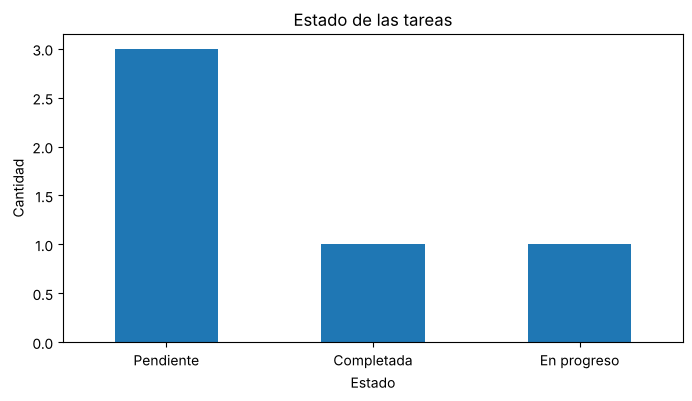

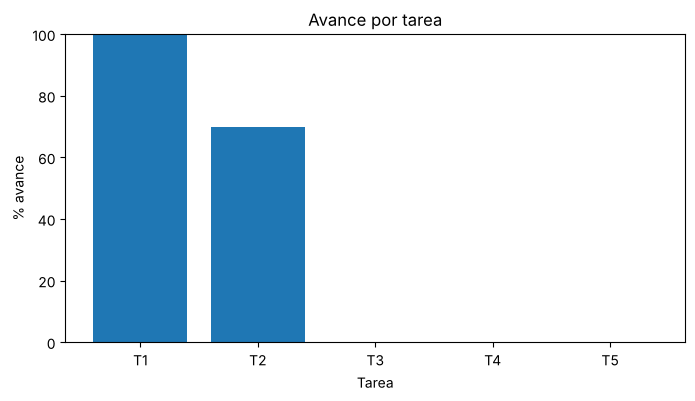

In [10]:
resumen_estados = tareas["estado"].value_counts()

plt.figure(figsize=(8, 4))
resumen_estados.plot(kind="bar")
plt.title("Estado de las tareas")
plt.xlabel("Estado")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(tareas["id"], tareas["avance_pct"])
plt.title("Avance por tarea")
plt.xlabel("Tarea")
plt.ylabel("% avance")
plt.ylim(0, 100)
plt.show()

## 10. Reporte ejecutivo automático

Este resumen es el puente hacia la plantilla Word.

In [11]:
print("=" * 60)
print("REPORTE DE MONITOREO · EDUALERT")
print("=" * 60)
print(f"Avance general: {avance_general:.1f}%")
print(f"Estado general: {semaforo}")
print(f"Tareas completadas: {kpis['Tareas completadas']}")
print(f"Tareas con desviación: {kpis['Tareas con desviación']}")
print(f"Tareas bloqueadas: {kpis['Tareas bloqueadas']}")
print(f"Desviación total de esfuerzo: +{kpis['Desviación total de horas']} h")
print()
print("Principal desviación: limpieza de registros requiere más esfuerzo.")
print("Causa:", causa_principal)
print("Impacto:", impacto_principal)
print("Acción:", accion_correctiva)

REPORTE DE MONITOREO · EDUALERT
Avance general: 34.0%
Estado general: ROJO
Tareas completadas: 1
Tareas con desviación: 1
Tareas bloqueadas: 3
Desviación total de esfuerzo: +3 h

Principal desviación: limpieza de registros requiere más esfuerzo.
Causa: Se encontró una cantidad mayor de valores faltantes que la prevista.
Impacto: T3 no puede iniciar y se retrasa el entrenamiento del modelo.
Acción: Asignar apoyo adicional a limpieza y postergar una tarea secundaria.


# PARTE 2 · AHORA SU PROYECTO

## 11. Reemplacen el ejemplo

Usen lo escrito en la microactividad.

Cambien únicamente los valores de la tabla de la siguiente celda.

**No inventen tareas nuevas para llenar el Colab:** usen tareas reales de su proyecto.

### Evidencia real del dataset `insurance.csv`
Antes de cargar las tareas, verificamos con el dataset lo que respalda el estado de T1 y T2.

In [12]:
# EVIDENCIA REAL DEL DATASET (respalda el estado de T1 y T2)
import os
ruta = next((p for p in ["insurance.csv", "../insurance.csv"] if os.path.exists(p)),
            "https://raw.githubusercontent.com/Catal2s/SCY1102/main/insurance.csv")
datos = pd.read_csv(ruta)

nulos = int(datos.isna().sum().sum())
duplicados = int(datos.duplicated().sum())
datos_sin_dup = datos.drop_duplicates()

q1, q3 = datos_sin_dup["charges"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
atipicos = datos_sin_dup[datos_sin_dup["charges"] > limite]

print(f"Registros originales: {len(datos)}")
print(f"Nulos: {nulos} | Duplicados: {duplicados} -> quedan {len(datos_sin_dup)} registros")
print(f"Atípicos en charges (IQR, > {limite:,.0f} USD): {len(atipicos)} ({len(atipicos)/len(datos_sin_dup):.1%})")
print(f"De esos atípicos, fumadores: {(atipicos['smoker'] == 'yes').mean():.1%}")
print(f"Mediana charges: {datos_sin_dup['charges'].median():,.0f} USD | Media: {datos_sin_dup['charges'].mean():,.0f} USD")

Registros originales: 1338
Nulos: 0 | Duplicados: 1 -> quedan 1337 registros
Atípicos en charges (IQR, > 34,525 USD): 139 (10.4%)
De esos atípicos, fumadores: 97.8%
Mediana charges: 9,386 USD | Media: 13,279 USD


In [13]:
# DATOS DEL GRUPO · Predicción de costos médicos (aseguradora de salud privada)
# Hito trabajado: H1 · Dataset de seguros médicos limpio y validado

mi_proyecto = pd.DataFrame([
    {
        "id": "T1",
        "hito": "H1 Dataset de seguros limpio",
        "tarea": "Cargar dataset y revisar nulos y duplicados",
        "responsable": "Integrante 1",
        "horas_plan": 2,
        "horas_real": 2,
        "estado": "Completada",       # Pendiente / En progreso / Completada
        "avance_pct": 100,
        "dependencia": "",
        "evidencia": "Reporte: 0 nulos, 1 duplicado eliminado (1338 -> 1337 filas)"
    },
    {
        "id": "T2",
        "hito": "H1 Dataset de seguros limpio",
        "tarea": "Analizar valores atípicos de charges y bmi",
        "responsable": "Integrante 2",
        "horas_plan": 2,
        "horas_real": 5,
        "estado": "En progreso",
        "avance_pct": 60,
        "dependencia": "T1",
        "evidencia": "Boxplots + conteo IQR: 139 atípicos en charges"
    },
    {
        "id": "T3",
        "hito": "H1 Dataset de seguros limpio",
        "tarea": "Codificar sex, smoker y region y definir X e y",
        "responsable": "Integrante 3",
        "horas_plan": 1,
        "horas_real": 0,
        "estado": "Pendiente",
        "avance_pct": 0,
        "dependencia": "T2",
        "evidencia": ""
    },
    {
        "id": "T4",
        "hito": "H1 Dataset de seguros limpio",
        "tarea": "Validar dataset y guardar versión limpia",
        "responsable": "Integrante 4",
        "horas_plan": 1,
        "horas_real": 0,
        "estado": "Pendiente",
        "avance_pct": 0,
        "dependencia": "T3",
        "evidencia": ""
    }
])

mi_proyecto

,id,hito,tarea,responsable,horas_plan,horas_real,estado,avance_pct,dependencia,evidencia
0,T1,H1 Dataset de seguros limpio,Cargar dataset y revisar nulos y duplicados,Integrante 1,2,2,Completada,100,,"Reporte: 0 nulos, 1 duplicado eliminado (1338 ..."
1,T2,H1 Dataset de seguros limpio,Analizar valores atípicos de charges y bmi,Integrante 2,2,5,En progreso,60,T1,Boxplots + conteo IQR: 139 atípicos en charges
2,T3,H1 Dataset de seguros limpio,"Codificar sex, smoker y region y definir X e y",Integrante 3,1,0,Pendiente,0,T2,
3,T4,H1 Dataset de seguros limpio,Validar dataset y guardar versión limpia,Integrante 4,1,0,Pendiente,0,T3,


## 12. Calcular automáticamente el estado de su proyecto

In [14]:
def analizar_proyecto(df):
    df = df.copy()

    estado_por_id = dict(zip(df["id"], df["estado"]))

    def bloqueada(dep):
        if dep == "" or pd.isna(dep):
            return False
        return estado_por_id.get(dep) != "Completada"

    df["bloqueada"] = df["dependencia"].apply(bloqueada)
    df["desviacion_horas"] = df["horas_real"] - df["horas_plan"]

    avance = df["avance_pct"].mean()
    completadas = int((df["estado"] == "Completada").sum())
    desviadas = int((df["desviacion_horas"] > 0).sum())
    bloqueadas = int(df["bloqueada"].sum())
    desvio_total = int(df["desviacion_horas"].clip(lower=0).sum())

    if bloqueadas >= 2 or desvio_total >= 3:
        semaforo = "ROJO"
    elif bloqueadas == 1 or avance < 70:
        semaforo = "AMARILLO"
    else:
        semaforo = "VERDE"

    resumen = {
        "Avance general (%)": round(avance, 1),
        "Tareas completadas": completadas,
        "Tareas con desviación": desviadas,
        "Tareas bloqueadas": bloqueadas,
        "Desviación total de horas": desvio_total,
        "Semáforo": semaforo
    }

    return df, resumen

mi_proyecto_analizado, resumen = analizar_proyecto(mi_proyecto)

display(mi_proyecto_analizado)
display(pd.DataFrame(resumen.items(), columns=["Indicador", "Resultado"]))

,id,hito,tarea,responsable,horas_plan,horas_real,estado,avance_pct,dependencia,evidencia,bloqueada,desviacion_horas
0,T1,H1 Dataset de seguros limpio,Cargar dataset y revisar nulos y duplicados,Integrante 1,2,2,Completada,100,,"Reporte: 0 nulos, 1 duplicado eliminado (1338 ...",False,0
1,T2,H1 Dataset de seguros limpio,Analizar valores atípicos de charges y bmi,Integrante 2,2,5,En progreso,60,T1,Boxplots + conteo IQR: 139 atípicos en charges,False,3
2,T3,H1 Dataset de seguros limpio,"Codificar sex, smoker y region y definir X e y",Integrante 3,1,0,Pendiente,0,T2,,True,-1
3,T4,H1 Dataset de seguros limpio,Validar dataset y guardar versión limpia,Integrante 4,1,0,Pendiente,0,T3,,True,-1


,Indicador,Resultado
0,Avance general (%),40.0
1,Tareas completadas,1
2,Tareas con desviación,1
3,Tareas bloqueadas,2
4,Desviación total de horas,3
5,Semáforo,ROJO


## 13. Identificar la principal alerta

Revisen:

- tareas con desviación positiva;
- tareas bloqueadas;
- tareas con bajo avance;
- el hito que podría verse afectado.

In [15]:
alertas = mi_proyecto_analizado[
    (mi_proyecto_analizado["desviacion_horas"] > 0) |
    (mi_proyecto_analizado["bloqueada"] == True) |
    ((mi_proyecto_analizado["estado"] != "Completada") & (mi_proyecto_analizado["avance_pct"] < 50))
]

display(alertas[[
    "id", "hito", "tarea", "responsable",
    "estado", "avance_pct", "desviacion_horas",
    "dependencia", "bloqueada"
]])

,id,hito,tarea,responsable,estado,avance_pct,desviacion_horas,dependencia,bloqueada
1,T2,H1 Dataset de seguros limpio,Analizar valores atípicos de charges y bmi,Integrante 2,En progreso,60,3,T1,False
2,T3,H1 Dataset de seguros limpio,"Codificar sex, smoker y region y definir X e y",Integrante 3,Pendiente,0,-1,T2,True
3,T4,H1 Dataset de seguros limpio,Validar dataset y guardar versión limpia,Integrante 4,Pendiente,0,-1,T3,True


**Lectura de las alertas:** la alerta principal es **T2**: es la única con desviación positiva (+3 h) y es la causa raíz. T3 y T4 aparecen porque están bloqueadas por la cadena T2 → T3 → T4. El hito afectado es **H1 · Dataset de seguros médicos limpio y validado**.

## 14. Decisión del equipo

Completen estas cuatro variables con su análisis.

La respuesta debe seguir la secuencia:

**Desviación → Causa → Impacto → Acción**

In [16]:
principal_desviacion = "T2 (analizar valores atípicos) lleva 5 h reales contra 2 h planificadas: +3 h, con 60 % de avance."
principal_causa = "Se detectaron 139 atípicos en charges (10,4 %); al revisarlos, el 97,8 % son fumadores: son casos reales, no errores."
principal_impacto = "T3 y T4 quedan bloqueadas; el hito H1 pasa del miércoles 4 al jueves 5 de noviembre (+1 día) y H2 (modelo base) se corre igual."
accion_correctiva = "Mantener y documentar los atípicos, dejar el análisis de bmi como mejora y el Integrante 1 apoya 1 h para cerrar T2. Responsable: Integrante 2. Revisión: martes 3/11."

print("DESVIACIÓN:", principal_desviacion)
print("CAUSA:", principal_causa)
print("IMPACTO:", principal_impacto)
print("ACCIÓN:", accion_correctiva)

DESVIACIÓN: T2 (analizar valores atípicos) lleva 5 h reales contra 2 h planificadas: +3 h, con 60 % de avance.
CAUSA: Se detectaron 139 atípicos en charges (10,4 %); al revisarlos, el 97,8 % son fumadores: son casos reales, no errores.
IMPACTO: T3 y T4 quedan bloqueadas; el hito H1 pasa del miércoles 4 al jueves 5 de noviembre (+1 día) y H2 (modelo base) se corre igual.
ACCIÓN: Mantener y documentar los atípicos, dejar el análisis de bmi como mejora y el Integrante 1 apoya 1 h para cerrar T2. Responsable: Integrante 2. Revisión: martes 3/11.


## 15. Dashboard del grupo

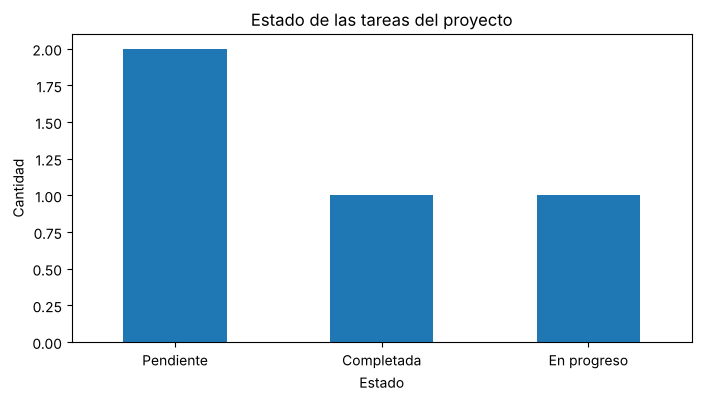

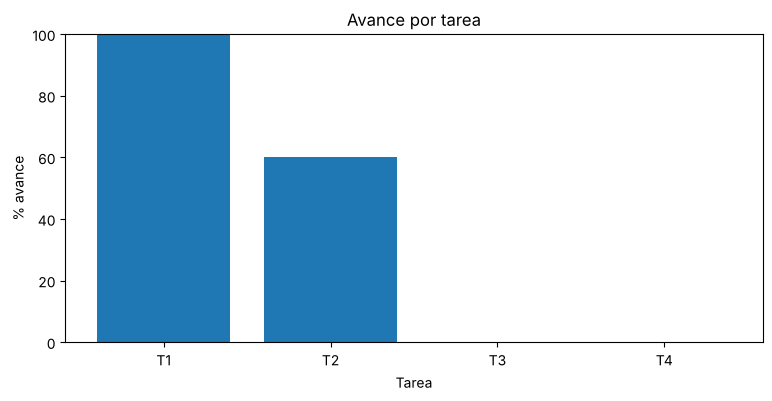

In [17]:
plt.figure(figsize=(8, 4))
mi_proyecto_analizado["estado"].value_counts().plot(kind="bar")
plt.title("Estado de las tareas del proyecto")
plt.xlabel("Estado")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(mi_proyecto_analizado["id"], mi_proyecto_analizado["avance_pct"])
plt.title("Avance por tarea")
plt.xlabel("Tarea")
plt.ylabel("% avance")
plt.ylim(0, 100)
plt.show()

**Lectura del dashboard:** 1 tarea completada, 1 en progreso y 2 pendientes. El avance se corta en T2: todo lo que depende de ella sigue en 0 %.

## 16. Reporte para copiar a la plantilla Word

In [18]:
print("=" * 60)
print("REPORTE DE MONITOREO · PREDICCIÓN DE COSTOS MÉDICOS")
print("=" * 60)

for clave, valor in resumen.items():
    print(f"{clave}: {valor}")

print()
print("Principal desviación:", principal_desviacion)
print("Causa:", principal_causa)
print("Impacto:", principal_impacto)
print("Acción correctiva:", accion_correctiva)

REPORTE DE MONITOREO · PREDICCIÓN DE COSTOS MÉDICOS
Avance general (%): 40.0
Tareas completadas: 1
Tareas con desviación: 1
Tareas bloqueadas: 2
Desviación total de horas: 3
Semáforo: ROJO

Principal desviación: T2 (analizar valores atípicos) lleva 5 h reales contra 2 h planificadas: +3 h, con 60 % de avance.
Causa: Se detectaron 139 atípicos en charges (10,4 %); al revisarlos, el 97,8 % son fumadores: son casos reales, no errores.
Impacto: T3 y T4 quedan bloqueadas; el hito H1 pasa del miércoles 4 al jueves 5 de noviembre (+1 día) y H2 (modelo base) se corre igual.
Acción correctiva: Mantener y documentar los atípicos, dejar el análisis de bmi como mejora y el Integrante 1 apoya 1 h para cerrar T2. Responsable: Integrante 2. Revisión: martes 3/11.


# CIERRE

Antes de terminar, el grupo debe poder responder:

1. ¿Cuál es nuestro próximo hito?
2. ¿Qué tarea está más en riesgo?
3. ¿Qué dependencia está bloqueando trabajo?
4. ¿Cuál es nuestra principal desviación?
5. ¿Qué acción concreta tomaremos?
6. ¿Qué evidencia mostraremos la próxima semana?

Después de completar el Colab:

**actualicen Jira/Trello y registren la misma decisión.**

## Respuestas de cierre · Predicción de costos médicos

1. **¿Cuál es nuestro próximo hito?** H1 · Dataset de seguros médicos limpio y validado (jueves 5/11); después, H2 · Modelo base de regresión entrenado y evaluado.
2. **¿Qué tarea está más en riesgo?** T2 · Analizar valores atípicos (60 %, +3 h).
3. **¿Qué dependencia está bloqueando trabajo?** T3 depende de T2 y T4 de T3: 2 tareas bloqueadas.
4. **¿Cuál es nuestra principal desviación?** +3 h en T2 por 139 atípicos que hubo que investigar.
5. **¿Qué acción concreta tomaremos?** Mantener y documentar los atípicos, dejar bmi como mejora y apoyo de 1 h del Integrante 1.
6. **¿Qué evidencia mostraremos la próxima semana?** insurance_limpio_v1.csv (1337 filas) + notebook ejecutado + tablero actualizado.

**Tablero (Jira/Trello):** T2 queda *En progreso* con la desviación y la acción registradas; T3 y T4 quedan *Bloqueadas por T2*; la fecha de H1 pasa al jueves 5/11.